# 01 · Preprocessing and the window sample

**What this notebook does.**  It turns the UV cube from notebook 00 into the
analysis sample: **46 windows, each 0.48 ly (150 px) square**, tiling one
contiguous region of the cloud.  It also shows how each window is read and
normalised before its structure function is computed.

**Why these steps.**
- **Edge erosion.**  The resampling repeats edge values near the boundary of
  each epoch's footprint, so pixels within 50 px of missing data are dropped.
- **Per-epoch normalisation.**  The echo brightens with depth and the epochs
  differ in overall brightness.  Scaling each epoch to a common rms in each
  window removes this, so the structure function measures *morphology*, not
  brightness changes.
- **Selection by structure, not brightness.**  The sky level drifts across the
  mosaic and faint gas can fill a window completely.  A window therefore
  belongs to the cloud if it shows *resolved structure* above the noise in
  every epoch, whatever its brightness.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

from mabsf import config as C, data as D, preprocess as P, plotting
from mabsf.checks import check, targets

plotting.style()
cfg = C.Config()          # the paper's analysis choices
cube = D.uv_cube('draw1'); Ug, Vg = D.uv_grids()
cfg

Config(epochs=(0, 1, 2, 3, 4, 5, 6), infill='draw1', norm='window', size=150, shift=(0, 0), on_k=2.0, smooth=25, frac=0.9, centres='tiles', rcut=0.1, rmin=0.0, weighting='1/r', K=4, inner_uv=45, stride=2, sigma=0.0325, calib='dedup', t2min=0.05, degen=0.02, collapsed='include')

## 1. Reading a window

`read_window` cuts a square from the cube, subtracts each epoch's sky level
and applies the edge erosion.  `normalise` then scales each epoch by
median(rms) / rms_k.  Below is Region 1 (a window of the sample): its epochs
before and after normalisation.

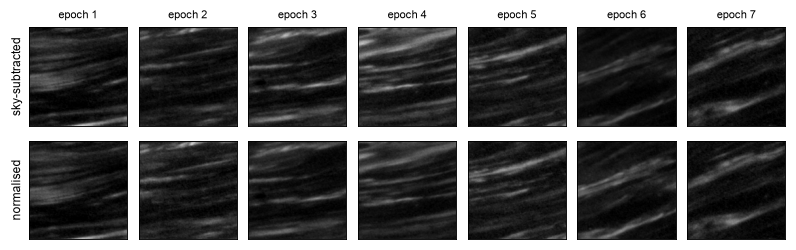

,epoch,rms,scale
0,1,0.0590,0.923
1,2,0.0449,1.213
2,3,0.0693,0.786
3,4,0.0746,0.729
4,5,0.0514,1.060
5,6,0.0364,1.496
6,7,0.0544,1.000


In [2]:
r1 = (C.REGION_CENTERS[1][0] - 75, C.REGION_CENTERS[1][1] - 75)
raw = P.read_window(*r1, cfg.size)
nrm = P.normalise(raw)
fig, axs = plt.subplots(2, 7, figsize=(plotting.W_IN, 2.4))
for k in range(7):
    axs[0, k].imshow(raw['flux_epochs'][k], origin='lower', cmap='gray', vmin=0, vmax=0.6)
    axs[1, k].imshow(nrm['flux_epochs'][k], origin='lower', cmap='gray', vmin=0, vmax=0.6)
    axs[0, k].set_title('epoch %d' % (k + 1), fontsize=7)
for a in axs.flat:
    a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_ylabel('sky-subtracted'); axs[1, 0].set_ylabel('normalised')
fig.tight_layout()
pd.DataFrame(dict(epoch=np.arange(1, 8), rms=nrm['epoch_rms'].round(4),
                  scale=(np.median(nrm['epoch_rms']) / nrm['epoch_rms']).round(3)))

The epochs' rms differ by a factor of two in this window (0.036-0.075):
the structure's contrast changes from slice to slice.  After normalisation
all seven have the same rms, so S2 compares shapes, not brightness.

## 2. Structure maps

Each epoch is band-passed with the difference of two Gaussians, sigma 2 px
minus sigma 30 px (both normalised for missing pixels).  This keeps
fluctuations on ~0.01-0.1 ly, the scales the shape fit uses, and removes both
pixel noise and the smooth brightness level.

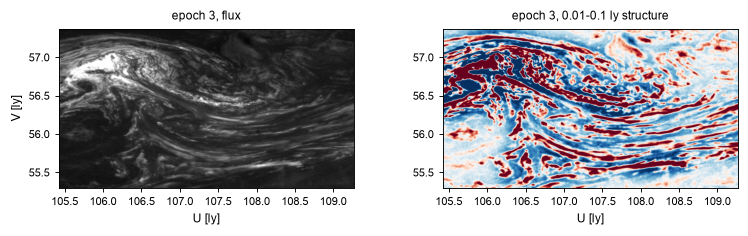

In [3]:
P.band_maps()
v0, v1, u0, u1 = 1700, 2350, 1300, 2500
fig, axs = plt.subplots(1, 2, figsize=(plotting.W_IN, 2.0))
ext = [Ug[0, u0], Ug[0, u1 - 1], Vg[v0, 0], Vg[v1 - 1, 0]]
axs[0].imshow(np.asarray(cube[2, v0:v1, u0:u1]), origin='lower', cmap='gray', vmin=0.3, vmax=1.1, extent=ext)
axs[1].imshow(np.asarray(P.band(2)[v0:v1, u0:u1]), origin='lower', cmap='RdBu_r', vmin=-0.08, vmax=0.08, extent=ext)
axs[0].set_title('epoch 3, flux'); axs[1].set_title('epoch 3, 0.01-0.1 ly structure')
for a in axs:
    a.set_xlabel('U [ly]')
axs[0].set_ylabel('V [ly]')
fig.tight_layout()

## 3. Noise level of each epoch

The band-pass map is cut into 25 px (0.08 ly) blocks and the rms of each block
is measured.  Blocks outside a hand-drawn polygon around the cloud are empty
sky; the 20th percentile of their rms is that epoch's noise.  The polygon is
used *only* here.

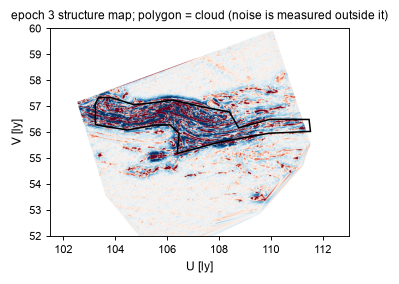

,epoch,sky_noise
0,1,0.00358
1,2,0.00364
2,3,0.00364
3,4,0.00366
4,5,0.00386
5,6,0.00243
6,7,0.00368


In [4]:
nz = P.noise_levels()
fig, ax = plt.subplots(figsize=(plotting.W_IN, 2.6))
sl = (slice(None, None, 4), slice(None, None, 4))
ax.imshow(np.asarray(P.band(2))[sl], origin='lower', cmap='RdBu_r', vmin=-0.05, vmax=0.05,
          extent=[Ug[0, 0], Ug[0, -1], Vg[0, 0], Vg[-1, 0]])
ax.add_patch(Polygon(C.cloud_polygon_uv(), fc='none', ec='k', lw=1.0))
ax.set_xlim(101.5, 113); ax.set_ylim(52, 60); ax.set_xlabel('U [ly]'); ax.set_ylabel('V [ly]')
ax.set_title('epoch 3 structure map; polygon = cloud (noise is measured outside it)')
fig.tight_layout()
pd.DataFrame(dict(epoch=np.arange(1, 8), sky_noise=nz.round(5)))

## 4. The cloud region

At each pixel, the local rms of the structure map (25 px box) divided by that
epoch's noise gives a structure-to-noise ratio.  Its **minimum over the seven
epochs** is kept, so gas that appears or disappears with depth does not
count.  This map is smoothed by 0.08 ly and thresholded at 2.  Enclosed holes
are filled and the largest connected piece is kept.  The cloud is defined
once, independently of where windows are placed or how they fit.

cloud region: 1418131 px = 14.52 ly^2


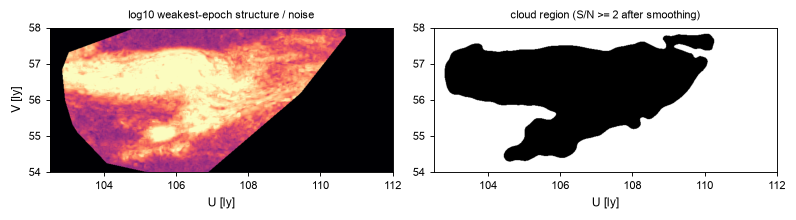

In [5]:
sn = np.asarray(P.weakest_epoch_sn())
reg = P.cloud_region(cfg.on_k, cfg.smooth)
fig, axs = plt.subplots(1, 2, figsize=(plotting.W_IN, 2.4))
for a, im, t in ((axs[0], np.log10(np.maximum(sn, 0.1))[sl], 'log10 weakest-epoch structure / noise'),
                 (axs[1], reg[sl], 'cloud region (S/N >= 2 after smoothing)')):
    h = a.imshow(im, origin='lower', extent=[Ug[0, 0], Ug[0, -1], Vg[0, 0], Vg[-1, 0]],
                 cmap='magma' if a is axs[0] else 'Greys', vmin=-1 if a is axs[0] else 0, vmax=1)
    a.set_xlim(102.5, 112); a.set_ylim(54, 58); a.set_title(t, fontsize=7); a.set_xlabel('U [ly]')
axs[0].set_ylabel('V [ly]')
fig.tight_layout()
print('cloud region: %d px = %.2f ly^2' % (reg.sum(), reg.sum() * C.PIX_LY ** 2))

## 5. Tiling into windows

The windows are non-overlapping 150 px tiles on a grid anchored so that
Region 1's box is one of the tiles.  A tile is kept if at least 90% of it lies
in the cloud region and all seven epochs cover it.

46 windows


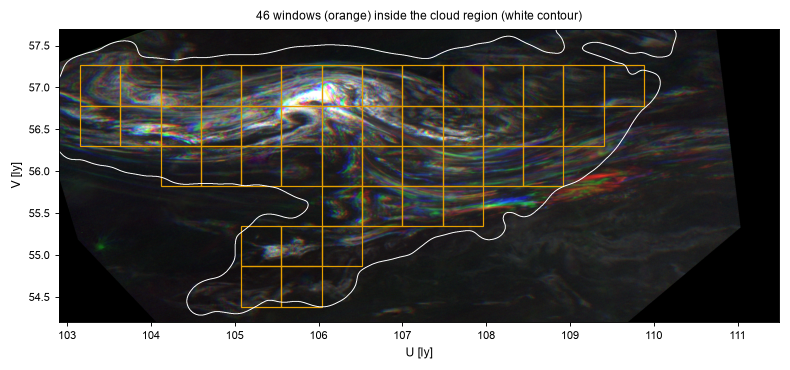

In [6]:
wins = P.sample_windows(cfg)
print(len(wins), 'windows')
fig, ax = plt.subplots(figsize=(plotting.W_IN, 3.2))
ulim, vlim = (102.9, 111.5), (54.2, 57.7)
r0, r1_ = np.searchsorted(Vg[:, 0], vlim); c0, c1 = np.searchsorted(Ug[0], ulim)
ax.imshow(plotting.rgb_composite(np.asarray(cube[:, r0:r1_, c0:c1])), origin='lower',
          extent=[Ug[0, c0], Ug[0, c1 - 1], Vg[r0, 0], Vg[r1_ - 1, 0]])
ax.contour(Ug[0, c0:c1], Vg[r0:r1_, 0], reg[r0:r1_, c0:c1], levels=[0.5], colors='w', linewidths=0.6)
for r, c in wins:
    ax.add_patch(Rectangle((Ug[0, c], Vg[r, 0]), cfg.size * C.PIX_LY, cfg.size * C.PIX_LY,
                           fc='none', ec=plotting.C_WIN, lw=0.8))
ax.set_xlabel('U [ly]'); ax.set_ylabel('V [ly]')
ax.set_title('46 windows (orange) inside the cloud region (white contour)')
fig.tight_layout()

## 6. Check against the published analysis

In [7]:
T = targets()['sample']
check('number of windows', len(wins), T['n'], rtol=0)
check('window corners (row, col)', sorted(wins), sorted(map(tuple, T['windows'])), rtol=0)
check('cloud region size [px]', reg.sum(), T['region_npix'], rtol=0)
check('sky noise per epoch', nz, T['noise_levels'], rtol=1e-10)

ok   number of windows                                46  (expected 46)
ok   window corners (row, col)                        [92 values, max |diff| 0]  (expected )
ok   cloud region size [px]                           1.41813e+06  (expected 1.41813e+06)
ok   sky noise per epoch                              [0.00358 0.00364 0.00364 0.00366 0.00386 0.00243 0.00368]  (expected [0.00358 0.00364 0.00364 0.00366 0.00386 0.00243 0.00368])
